# Evaluación del modelo toy

Un poco más complejo q el de la E1, con feedback y mejoras implentadas
]

### 1. Definir toy model simple

In [1]:
import cobra

def modelo_toy_simple():
    """
    Crea un modelo toy simple con tres especies: B1, B2 y B3.
    B1: auxótrofo de glutamato
    B2: no usa glucosa, vive del acetato de B1
    B3: sin respiración, compite con B1 por glucosa
    """
    base = cobra.io.load_model("textbook")
    B1, B2, B3 = base.copy(), base.copy(), base.copy()
    # B1: auxótrofo de glutamato
    B1.reactions.get_by_id("GLUDy").bounds = (0, 0)
    B1.reactions.get_by_id("GLUSy").bounds = (0, 0)
    # B2: no usa glucosa, vive del acetato de B1
    B2.reactions.get_by_id("GLCpts").bounds = (0, 0)
    # B3: sin respiración, compite con B1 por glucosa
    B3.reactions.get_by_id("CYTBD").bounds = (0, 0)
    modelos = {"B1": B1, "B2": B2, "B3": B3}
    return modelos

# Medio de cultivo simple
MEDIO = {
    "glc__D_e": (-10, 100),
    "o2_e": (-15, 100),
    "nh4_e": (-100, 100),
    "pi_e": (-100, 100),
    "h2o_e": (-100, 100),
    "h_e": (-100, 100),
    "co2_e": (-100, 100)
}

# Medios de referencia para cada especie
MEDIOS_REF = {
    "B1": {**MEDIO, "glu__L_e": (-5, 100)},
    "B2": {**MEDIO, "ac_e": (-10, 100)}
}
# Medios individuales de referencia
medios_individuales = {
    "B1": MEDIOS_REF["B1"],  # Medio + glutamato
    "B2": MEDIOS_REF["B2"],  # Medio + acetato
    "B3": MEDIO              # Medio compartido
}

# Medio comunitario de referencia
medio_comunidad = MEDIO


### 2. Implementar metodo

In [2]:
# Importaciones necesarias
from metodo.community_moma import barrido_moma
from metodo.results import imprimir_resumen, graficar_comparacion
from metodo.referencias import calcular_referencias, imprimir_referencias
import numpy as np
import pandas as pd

In [3]:
# Evaluar referencias
modelos = modelo_toy_simple()
referencias = calcular_referencias(modelos, medio_comunidad,medios_individuales)
imprimir_referencias(referencias)

Set parameter Username
Set parameter LicenseID to value 2854514
Academic license - for non-commercial use only - expires 2027-08-19
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpxyym42tn.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp7812frov.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp3e4vvtqe.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpxszs16dg.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp0le5dr6z.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3x

In [4]:
# Barrido de crecimiento (Community MOMA) para diferentes valores de alpha
alphas = np.linspace(0.5, 1.0, 11)

resultados = barrido_moma(
    referencias=referencias,
    medio=MEDIO,
    alphas=alphas,
    eps=1e-4,
    pesos="norma",
    coexistencia=True
)

### 3. Resultados


In [5]:
df = imprimir_resumen(resultados)
columnas = [
    "alpha",
    "mu",
    "status",
    "factible",
    "objetivo",
    "B1_MOMA",
    "B2_MOMA",
    "B3_MOMA"
]
display(df[columnas])

COMPARACIÓN STEADYCOM vs COMMUNITY MOMA
Mu máximo SteadyCom reportado : 0.717834
Mu techo con coexistencia     : 0.717827

Abundancias de referencia SteadyCom:
  B1: 0.500000
  B2: 0.000000
  B3: 0.500000

Mayor mu MOMA factible en el barrido: 0.681936
Alpha correspondiente              : 0.950000


,alpha,mu,status,factible,objetivo,B1_MOMA,B2_MOMA,B3_MOMA
0,0.50,0.358913,Óptimo local,True,0.286813,0.580047,0.030246,0.389707
1,0.55,0.394805,Óptimo local,True,0.398607,0.599377,0.040040,0.360583
2,0.60,0.430696,Óptimo local,True,0.537833,0.617541,0.046133,0.336326
3,0.65,0.466587,Óptimo local,True,0.704652,0.634714,0.049071,0.316215
4,0.70,0.502479,Óptimo local,True,0.899881,0.656115,0.043810,0.300075
5,0.75,0.538370,Óptimo local,True,1.126821,0.672252,0.043666,0.284082
6,0.80,0.574261,Óptimo local,True,1.395492,0.681032,0.050838,0.268130
7,0.85,0.610153,Óptimo local,True,1.721771,0.656237,0.094934,0.248830
8,0.90,0.646044,Óptimo local,True,2.108017,0.626010,0.149675,0.224314
9,0.95,0.681936,Óptimo local,True,2.574987,0.637180,0.154516,0.208304


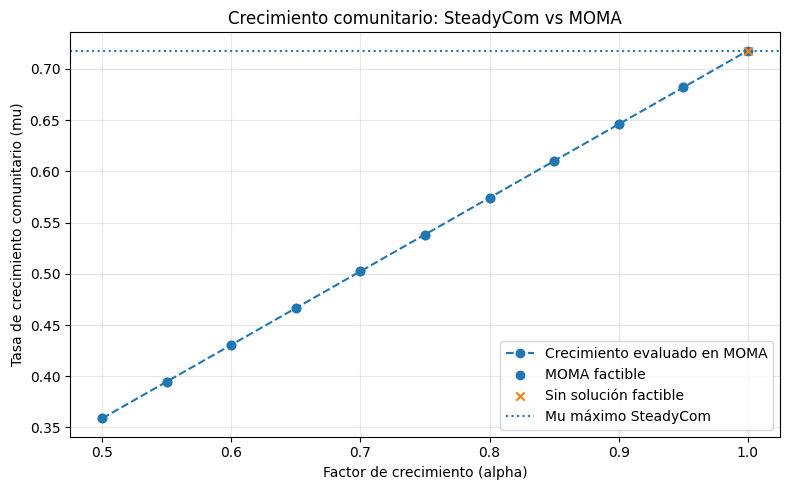

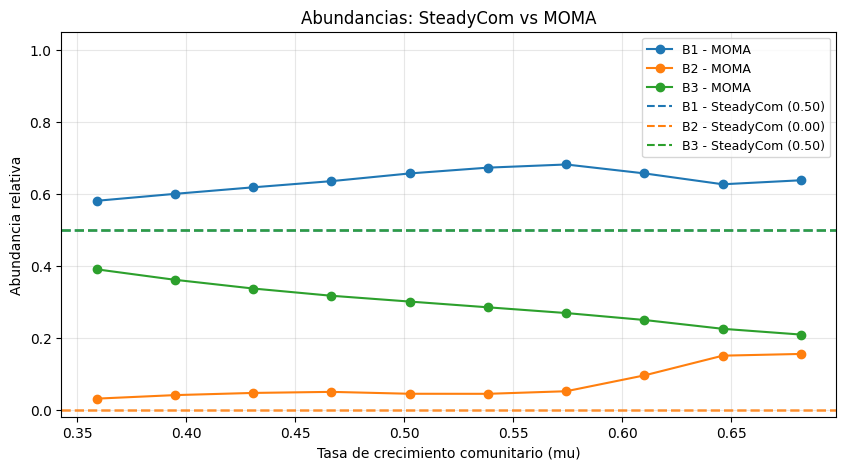

((<Figure size 800x500 with 1 Axes>,
  <Axes: title={'center': 'Crecimiento comunitario: SteadyCom vs MOMA'}, xlabel='Factor de crecimiento (alpha)', ylabel='Tasa de crecimiento comunitario (mu)'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Abundancias: SteadyCom vs MOMA'}, xlabel='Tasa de crecimiento comunitario (mu)', ylabel='Abundancia relativa'>))

In [6]:
graficar_comparacion(resultados)